# Validacao externa dos cinco algoritmos no ano de 2025

Este notebook avalia os cinco algoritmos sobre o ano de 2025, um periodo nunca usado em nenhuma decisao de ajuste, selecao de hiperparametros ou escolha de algoritmo ate este ponto do projeto.
O objetivo e verificar a estabilidade temporal do desempenho de cada algoritmo, comparando diretamente as metricas obtidas no teste de 2024, usado ate aqui como referencia principal, com as metricas obtidas em 2025.
O ano de 2025 tem prevalencia de obito bem mais baixa do que 2024, 2,75 por cento contra 5,23 por cento, o que por si so reduz o valor esperado da AUPRC em 2025 mesmo para um algoritmo com discriminacao identica, ja que a AUPRC de um classificador sem nenhum poder discriminativo e igual a prevalencia observada.
Por isso, alem da comparacao direta das metricas, este notebook tambem compara a razao entre a AUPRC de cada algoritmo e a prevalencia do respectivo ano, uma forma de normalizar a AUPRC pela mudanca de prevalencia e isolar a parte da queda de desempenho que nao se explica simplesmente por haver menos obitos para encontrar em 2025.

Importa as bibliotecas necessarias, inclui a raiz do projeto no caminho de importacao para reutilizar `utils/preprocessamento.py`, e cria o diretorio de saida usado ao longo do notebook.
A tabela comparativa final e salva em `analysis/results_avaliacao/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from utils import preprocessamento

DIRETORIO_METRICAS = PROJECT_ROOT / "output" / "metricas"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_avaliacao"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "avaliacao"
DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "arvore_decisao", "random_forest", "xgboost", "lightgbm"]

Carrega, para cada um dos cinco algoritmos, as predicoes de probabilidade e o alvo real do teste de 2024 e da validacao externa de 2025, e confirma a prevalencia observada de obito em cada um dos dois anos.

In [2]:
predicoes_teste2024 = {
    algoritmo: pd.read_parquet(DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024.parquet")
    for algoritmo in ALGORITMOS
}
predicoes_val2025 = {
    algoritmo: pd.read_parquet(DIRETORIO_METRICAS / f"{algoritmo}_predicoes_val2025.parquet")
    for algoritmo in ALGORITMOS
}

prevalencia_teste2024 = predicoes_teste2024[ALGORITMOS[0]]["obito"].mean()
prevalencia_val2025 = predicoes_val2025[ALGORITMOS[0]]["obito"].mean()

(
    len(predicoes_teste2024[ALGORITMOS[0]]),
    predicoes_teste2024[ALGORITMOS[0]]["obito"].sum(),
    prevalencia_teste2024,
    len(predicoes_val2025[ALGORITMOS[0]]),
    predicoes_val2025[ALGORITMOS[0]]["obito"].sum(),
    prevalencia_val2025,
)

(3978,
 np.int64(208),
 np.float64(0.05228758169934641),
 3241,
 np.int64(89),
 np.float64(0.02746066029003394))

Calcula AUPRC, ROC-AUC e Brier Score de cada algoritmo nos dois anos, usando `avaliar_predicoes` de `utils/preprocessamento.py`, e organiza o resultado numa tabela longa com uma linha por combinacao de algoritmo e metrica.

In [3]:
linhas_comparacao = []
for algoritmo in ALGORITMOS:
    metricas_teste2024 = preprocessamento.avaliar_predicoes(
        predicoes_teste2024[algoritmo]["obito"], predicoes_teste2024[algoritmo]["probabilidade_predita"]
    )
    metricas_val2025 = preprocessamento.avaliar_predicoes(
        predicoes_val2025[algoritmo]["obito"], predicoes_val2025[algoritmo]["probabilidade_predita"]
    )

    for nome_metrica in ["auprc", "roc_auc", "brier_score"]:
        valor_teste2024 = metricas_teste2024[nome_metrica]
        valor_val2025 = metricas_val2025[nome_metrica]
        linhas_comparacao.append(
            {
                "algoritmo": algoritmo,
                "metrica": nome_metrica,
                "teste2024": valor_teste2024,
                "val2025": valor_val2025,
                "diferenca_absoluta": valor_val2025 - valor_teste2024,
                "diferenca_percentual": (valor_val2025 - valor_teste2024) / valor_teste2024 * 100,
            }
        )

tabela_comparacao_2024_vs_2025 = pd.DataFrame(linhas_comparacao)
tabela_comparacao_2024_vs_2025

,algoritmo,metrica,teste2024,val2025,diferenca_absoluta,diferenca_percentual
0,regressao_logistica,auprc,0.224153,0.117988,-0.106165,-47.362808
1,regressao_logistica,roc_auc,0.820210,0.799353,-0.020857,-2.542860
2,regressao_logistica,brier_score,0.231823,0.212253,-0.019571,-8.442049
3,arvore_decisao,auprc,0.126649,0.079085,-0.047564,-37.555564
4,arvore_decisao,roc_auc,0.742949,0.723692,-0.019256,-2.591840
5,arvore_decisao,brier_score,0.207120,0.212404,0.005284,2.551405
6,random_forest,auprc,0.226905,0.120737,-0.106168,-46.789640
7,random_forest,roc_auc,0.812126,0.804390,-0.007736,-0.952568
8,random_forest,brier_score,0.066271,0.054261,-0.012010,-18.122836
9,xgboost,auprc,0.196472,0.044179,-0.152293,-77.513899


Calcula, para cada algoritmo, a razao entre a AUPRC e a prevalencia observada de obito no respectivo ano, chamada aqui de ganho sobre a prevalencia.
Essa razao normaliza a AUPRC pelo piso teorico de um classificador sem nenhum poder discriminativo, cuja AUPRC esperada e igual a propria prevalencia, o que permite comparar a capacidade relativa de discriminacao entre os dois anos apesar da queda de prevalencia de obito de 5,23 para 2,75 por cento.
O resultado e adicionado a tabela comparativa como linhas de uma metrica adicional, `ganho_auprc_sobre_prevalencia`.

In [4]:
linhas_ganho_sobre_prevalencia = []
for algoritmo in ALGORITMOS:
    auprc_teste2024 = tabela_comparacao_2024_vs_2025.loc[
        (tabela_comparacao_2024_vs_2025["algoritmo"] == algoritmo)
        & (tabela_comparacao_2024_vs_2025["metrica"] == "auprc"),
        "teste2024",
    ].iloc[0]
    auprc_val2025 = tabela_comparacao_2024_vs_2025.loc[
        (tabela_comparacao_2024_vs_2025["algoritmo"] == algoritmo)
        & (tabela_comparacao_2024_vs_2025["metrica"] == "auprc"),
        "val2025",
    ].iloc[0]

    ganho_teste2024 = auprc_teste2024 / prevalencia_teste2024
    ganho_val2025 = auprc_val2025 / prevalencia_val2025

    linhas_ganho_sobre_prevalencia.append(
        {
            "algoritmo": algoritmo,
            "metrica": "ganho_auprc_sobre_prevalencia",
            "teste2024": ganho_teste2024,
            "val2025": ganho_val2025,
            "diferenca_absoluta": ganho_val2025 - ganho_teste2024,
            "diferenca_percentual": (ganho_val2025 - ganho_teste2024) / ganho_teste2024 * 100,
        }
    )

tabela_comparacao_2024_vs_2025 = pd.concat(
    [tabela_comparacao_2024_vs_2025, pd.DataFrame(linhas_ganho_sobre_prevalencia)], ignore_index=True
)

tabela_comparacao_2024_vs_2025.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "comparacao_2024_vs_2025.csv", index=False
)
tabela_comparacao_2024_vs_2025.sort_values(["metrica", "algoritmo"]).reset_index(drop=True)

,algoritmo,metrica,teste2024,val2025,diferenca_absoluta,diferenca_percentual
0,arvore_decisao,auprc,0.126649,0.079085,-0.047564,-37.555564
1,lightgbm,auprc,0.195912,0.078388,-0.117524,-59.988251
2,random_forest,auprc,0.226905,0.120737,-0.106168,-46.789640
3,regressao_logistica,auprc,0.224153,0.117988,-0.106165,-47.362808
4,xgboost,auprc,0.196472,0.044179,-0.152293,-77.513899
5,arvore_decisao,brier_score,0.207120,0.212404,0.005284,2.551405
6,lightgbm,brier_score,0.180938,0.145884,-0.035054,-19.373436
7,random_forest,brier_score,0.066271,0.054261,-0.012010,-18.122836
8,regressao_logistica,brier_score,0.231823,0.212253,-0.019571,-8.442049
9,xgboost,brier_score,0.181249,0.135673,-0.045576,-25.145656


Gera um grafico de barras comparando a AUPRC e o ROC-AUC de cada algoritmo entre o teste de 2024 e a validacao externa de 2025, lado a lado, para visualizar diretamente a magnitude da queda de desempenho entre os dois anos.
O grafico e salvo em `analysis/plots/avaliacao/comparacao_metricas_2024_vs_2025.png`.

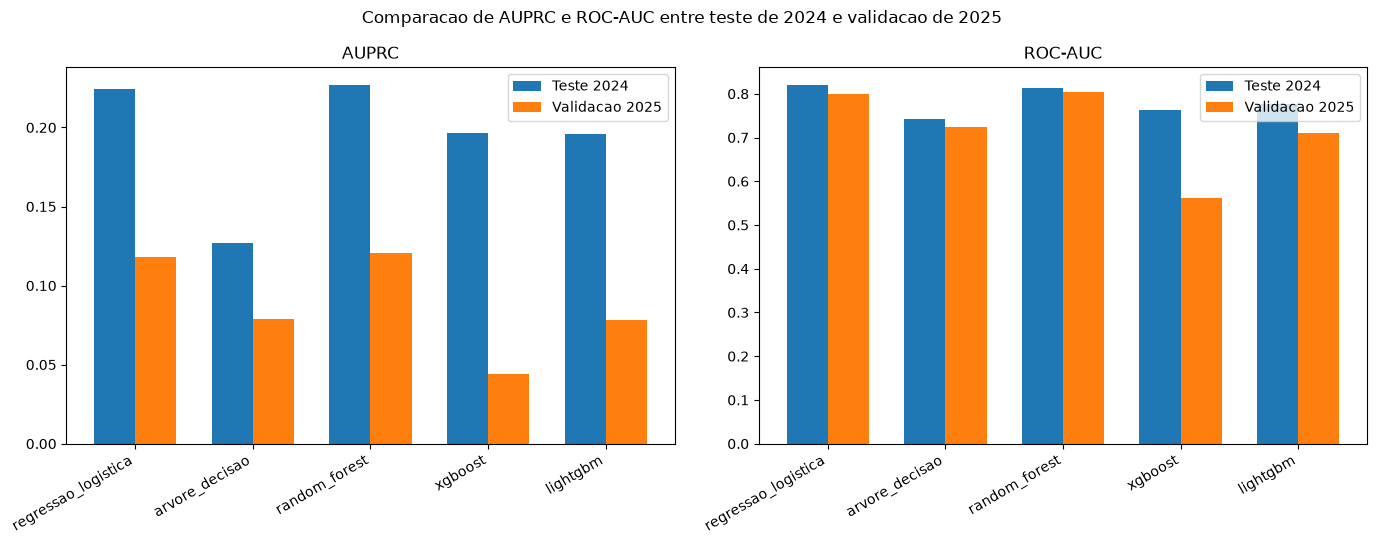

In [5]:
figura, eixos = plt.subplots(1, 2, figsize=(14, 5.5))

largura_barra = 0.35
posicoes = np.arange(len(ALGORITMOS))

for eixo_atual, nome_metrica, titulo in zip(eixos, ["auprc", "roc_auc"], ["AUPRC", "ROC-AUC"]):
    tabela_metrica = tabela_comparacao_2024_vs_2025[
        tabela_comparacao_2024_vs_2025["metrica"] == nome_metrica
    ].set_index("algoritmo").loc[ALGORITMOS]

    eixo_atual.bar(posicoes - largura_barra / 2, tabela_metrica["teste2024"], largura_barra, label="Teste 2024")
    eixo_atual.bar(posicoes + largura_barra / 2, tabela_metrica["val2025"], largura_barra, label="Validacao 2025")
    eixo_atual.set_xticks(posicoes)
    eixo_atual.set_xticklabels(ALGORITMOS, rotation=30, ha="right")
    eixo_atual.set_title(titulo)
    eixo_atual.legend()

figura.suptitle("Comparacao de AUPRC e ROC-AUC entre teste de 2024 e validacao de 2025")
figura.tight_layout()
figura.savefig(DIRETORIO_PLOTS / "comparacao_metricas_2024_vs_2025.png", dpi=150)
plt.show()

## Sintese dos achados

O XGBoost e, com folga, o algoritmo que mais degrada entre 2024 e 2025: seu ROC-AUC cai de 0,764 para 0,562, uma queda de 26,5 por cento que o deixa muito proximo do desempenho de um classificador aleatorio, cujo ROC-AUC esperado e 0,5, e sua AUPRC cai de 0,196 para 0,044, uma queda de 77,5 por cento.
Mesmo apos normalizar pela queda de prevalencia de obito entre os dois anos, de 5,23 para 2,75 por cento, o ganho de AUPRC do XGBoost sobre a prevalencia cai de 3,76 vezes em 2024 para apenas 1,61 vezes em 2025, uma queda que nao tem paralelo em nenhum dos outros quatro algoritmos e que indica perda real de capacidade discriminativa, nao apenas um efeito mecanico da menor prevalencia.
Random Forest e Regressao Logistica sao os algoritmos mais estaveis entre os dois anos, quando a comparacao e feita pelo ganho de AUPRC sobre a prevalencia: o Random Forest passa de 4,34 para 4,40 vezes a prevalencia, e a Regressao Logistica passa de 4,29 para 4,30 vezes a prevalencia, ou seja, a capacidade relativa de discriminacao desses dois algoritmos se mantem praticamente identica, apesar de a AUPRC absoluta de ambos cair por volta de 47 por cento, o que e consistente com a prevalencia de obito ter caido quase pela metade entre os dois anos.
O ROC-AUC do Random Forest e da Regressao Logistica tambem se mantem estavel, com queda de apenas 1 por cento e 2,5 por cento respectivamente, reforcando que a ordenacao de risco desses dois algoritmos generaliza bem para 2025.
A Arvore de Decisao e o LightGBM ficam numa posicao intermediaria: o ganho de AUPRC sobre a prevalencia da Arvore de Decisao sobe de 2,42 para 2,88 vezes, uma leve melhora relativa, enquanto o do LightGBM cai de 3,75 para 2,85 vezes, uma degradacao moderada, e o ROC-AUC do LightGBM cai de 0,776 para 0,709, uma queda de 8,6 por cento, mais acentuada do que a de Random Forest e Regressao Logistica mas muito distante do colapso observado no XGBoost.
O Brier Score melhora em 2025 para quatro dos cinco algoritmos, incluindo o do XGBoost, e piora ligeiramente apenas para a Arvore de Decisao, de 0,207 para 0,212, uma variacao de 2,6 por cento.
Essa melhora isolada do Brier Score na maioria dos algoritmos e esperada, dado que a prevalencia mais baixa de obito em 2025 reduz o piso teorico do Brier Score para qualquer modelo, e por isso nao deve ser lida como evidencia de melhora real de desempenho, ja contradita pela queda acentuada de AUPRC e de ROC-AUC do proprio XGBoost no mesmo periodo.
Em conjunto, estes resultados sugerem que, entre os cinco algoritmos avaliados nesta fase, o XGBoost e o menos indicado caso a estabilidade temporal seja um criterio relevante de selecao, enquanto Random Forest e Regressao Logistica sao os dois algoritmos cuja capacidade de discriminacao de risco se mostrou mais robusta entre o teste de 2024 e a validacao externa de 2025.